# Palier 1 · Les données et une baseline classique

## 1. Imports, graine et versions

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import tensorflow as tf
from tensorflow import keras

SEED = 42
keras.utils.set_random_seed(SEED)

print("Python      :", sys.version.split()[0])
print("NumPy       :", np.__version__)
print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("TensorFlow  :", tf.__version__)

Python      : 3.12.7
NumPy       : 2.5.5
pandas      : 3.1.1
scikit-learn: 1.9.1
TensorFlow  : 2.21.0


## 2. Chargement de MNIST

In [2]:
# MNIST est fourni directement par Keras (téléchargé la première fois, puis mis en cache)
(x_train_brut, y_train_brut), (x_test_brut, y_test_brut) = keras.datasets.mnist.load_data()

print("x_train :", x_train_brut.shape, x_train_brut.dtype)
print("y_train :", y_train_brut.shape, y_train_brut.dtype)
print("x_test  :", x_test_brut.shape, x_test_brut.dtype)
print("y_test  :", y_test_brut.shape, y_test_brut.dtype)
print("Pixels  : min =", x_train_brut.min(), "/ max =", x_train_brut.max())
print("Étiquettes :", np.unique(y_train_brut))

x_train : (60000, 28, 28) uint8
y_train : (60000,) uint8
x_test  : (10000, 28, 28) uint8
y_test  : (10000,) uint8
Pixels  : min = 0 / max = 255
Étiquettes : [0 1 2 3 4 5 6 7 8 9]


**Ce que j'observe :** il y a 60 000 images d'entraînement et 10 000 images de test, toutes en 28 × 28 pixels. Les pixels sont des entiers `uint8` entre 0 (fond) et 255 (trait). Il faudra les ramener entre 0 et 1 avant d'entraîner un modèle. Les étiquettes vont de 0 à 9, ce qui fait 10 classes.

## 3. Exploration : une grille d'images par classe

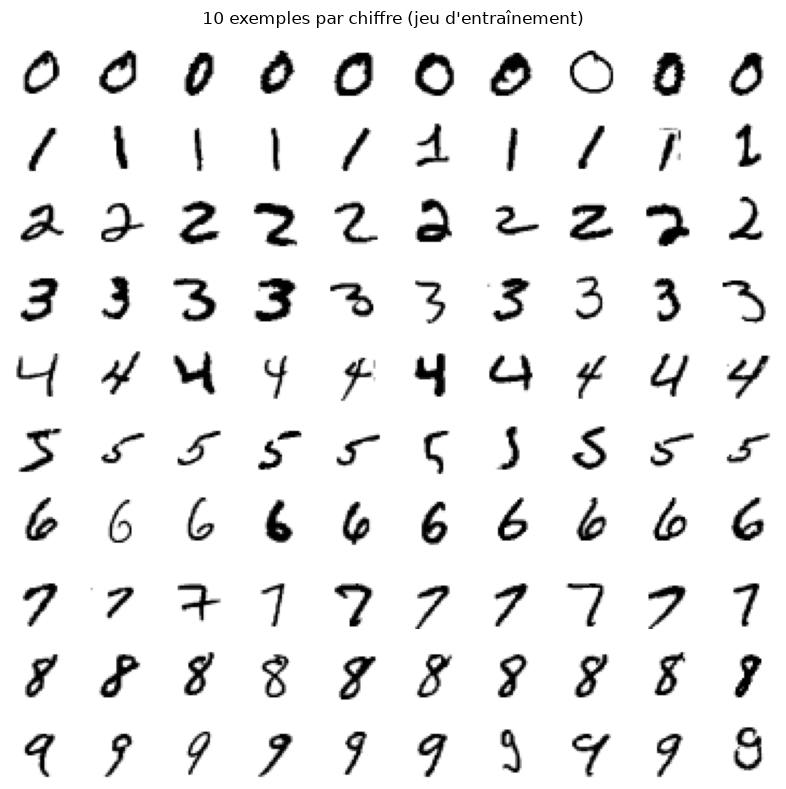

In [3]:
# Une ligne par chiffre, les 10 premiers exemples de chaque chiffre
fig, axes = plt.subplots(10, 10, figsize=(8, 8))
for chiffre in range(10):
    indices = np.where(y_train_brut == chiffre)[0][:10]
    for j, i in enumerate(indices):
        axes[chiffre, j].imshow(x_train_brut[i], cmap="gray_r")
        axes[chiffre, j].axis("off")
fig.suptitle("10 exemples par chiffre (jeu d'entraînement)")
plt.tight_layout()
plt.savefig("../images/p1_grille_chiffres.png", dpi=100, bbox_inches="tight")
plt.show()

Les chiffres sont centrés et ont à peu près la même taille, mais l'écriture varie beaucoup. Les 1 sont droits ou penchés, les 7 ont une barre ou pas, les 4 sont ouverts ou fermés, les 2 ont une boucle ou pas. Certains exemples seraient durs à lire même pour un humain : le 7e « 5 » ressemble à peine à un 5, et le dernier « 9 » ressemble à un 8.

*(J'affiche avec `cmap="gray_r"` pour avoir un trait noir sur fond blanc, mais dans les données le fond vaut 0.)*

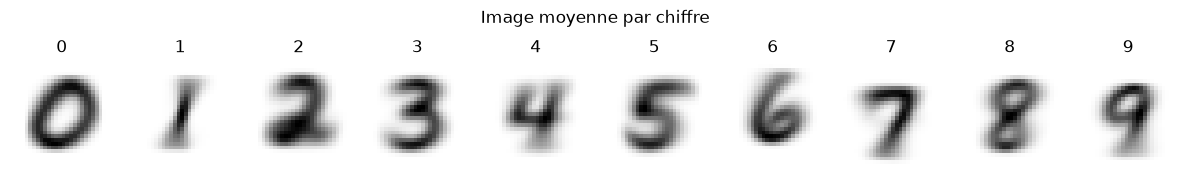

In [4]:
# Image moyenne de chaque chiffre : x[y == k].mean(axis=0)
fig, axes = plt.subplots(1, 10, figsize=(12, 1.8))
for k in range(10):
    axes[k].imshow(x_train_brut[y_train_brut == k].mean(axis=0), cmap="gray_r")
    axes[k].set_title(str(k))
    axes[k].axis("off")
fig.suptitle("Image moyenne par chiffre")
plt.tight_layout()
plt.savefig("../images/p1_images_moyennes.png", dpi=100, bbox_inches="tight")
plt.show()

Les images moyennes sont floues, mais chaque chiffre reste reconnaissable : pour un même chiffre, les pixels allumés sont souvent au même endroit. C'est pour ça qu'un modèle linéaire, qui donne un poids à chaque pixel, devrait déjà bien marcher. Le 1 est le plus net parce qu'il varie peu. Le 4 et le 9 se ressemblent beaucoup en moyenne, et je m'attends à ce qu'ils soient confondus.

## 4. Répartition des classes

In [5]:
# Nombre d'images par chiffre (on ne compte que les étiquettes, aucun modèle ici)
repartition = pd.DataFrame({
    "train": np.bincount(y_train_brut, minlength=10),
    "test": np.bincount(y_test_brut, minlength=10),
})
repartition.index.name = "chiffre"
repartition["train (%)"] = (100 * repartition["train"] / repartition["train"].sum()).round(2)
repartition["test (%)"] = (100 * repartition["test"] / repartition["test"].sum()).round(2)
print(repartition)
print()
print("Train : plus rare =", repartition["train"].idxmin(), f"({repartition['train'].min()})",
      "/ plus fréquent =", repartition["train"].idxmax(), f"({repartition['train'].max()})")
print("Test  : plus rare =", repartition["test"].idxmin(), f"({repartition['test'].min()})",
      "/ plus fréquent =", repartition["test"].idxmax(), f"({repartition['test'].max()})")

         train  test  train (%)  test (%)
chiffre                                  
0         5923   980       9.87      9.80
1         6742  1135      11.24     11.35
2         5958  1032       9.93     10.32
3         6131  1010      10.22     10.10
4         5842   982       9.74      9.82
5         5421   892       9.04      8.92
6         5918   958       9.86      9.58
7         6265  1028      10.44     10.28
8         5851   974       9.75      9.74
9         5949  1009       9.91     10.09

Train : plus rare = 5 (5421) / plus fréquent = 1 (6742)
Test  : plus rare = 5 (892) / plus fréquent = 1 (1135)


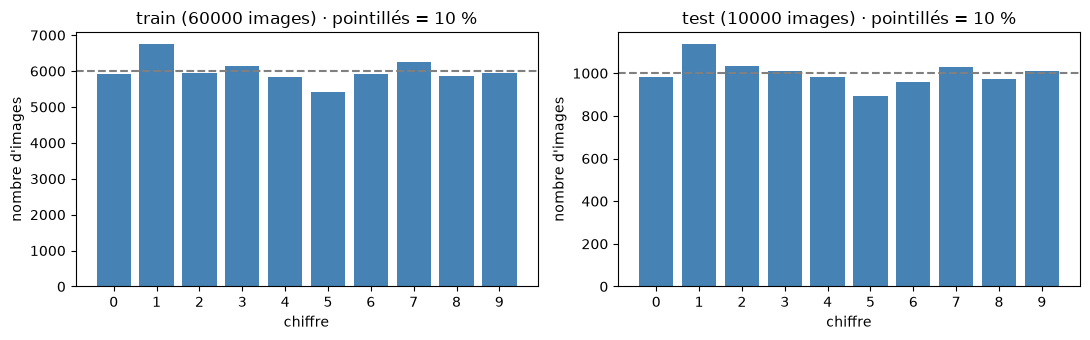

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, jeu, total in zip(axes, ["train", "test"], [len(y_train_brut), len(y_test_brut)]):
    ax.bar(repartition.index, repartition[jeu], color="steelblue")
    ax.axhline(total / 10, color="gray", linestyle="--")  # 10 % par chiffre = répartition parfaite
    ax.set_xticks(range(10))
    ax.set_xlabel("chiffre")
    ax.set_ylabel("nombre d'images")
    ax.set_title(f"{jeu} ({total} images) · pointillés = 10 %")
plt.tight_layout()
plt.savefig("../images/p1_repartition_classes.png", dpi=100, bbox_inches="tight")
plt.show()

**Est-ce équilibré ?** Oui, à peu près : chaque chiffre représente entre 9 % et 11,3 % des images (la répartition parfaite serait 10 %, en pointillés).

- La classe la plus **rare** est le **5** : 5 421 images en train (9,0 %) et 892 en test.
- La classe la plus **fréquente** est le **1** : 6 742 images en train (11,2 %) et 1 135 en test.

L'écart est trop petit pour fausser l'accuracy, donc pas besoin de rééquilibrer. Le test a presque les mêmes proportions que le train.

## 5. Mise à l'échelle et découpage entraînement / validation / test

On fait **trois tas** avec les données :

- **entraînement (54 000 images)** : le modèle apprend dessus ;
- **validation (6 000 images)** : sert à comparer les modèles et à choisir les réglages, ce sont les « contrôles blancs » ;
- **test (10 000 images)** : c'est le vrai contrôle, utilisé **une seule fois**, à la fin.

Si je choisissais mes réglages en regardant le test, je finirais par l'« apprendre » indirectement, et mon erreur finale serait trop optimiste. C'est pour ça qu'il faut trois tas et pas deux.

Le découpage est dans `src/data.py` (fonction `load_data`), pour que les trois notebooks utilisent exactement les mêmes jeux. `stratify=y` garde les mêmes proportions de chiffres dans l'entraînement et la validation.

In [7]:
# src/ est un dossier au-dessus de notebooks/
import sys
sys.path.append("..")
from src.data import load_data

x_train, y_train, x_val, y_val, x_test, y_test = load_data(seed=SEED)

print("train :", x_train.shape, y_train.shape)
print("val   :", x_val.shape, y_val.shape)
print("test  :", x_test.shape, y_test.shape)
print("Pixels : type", x_train.dtype, "/ min =", x_train.min(), "/ max =", x_train.max())

assert len(x_train) == 54_000 and len(x_val) == 6_000 and len(x_test) == 10_000
assert x_train.min() >= 0 and x_train.max() <= 1

train : (54000, 28, 28) (54000,)
val   : (6000, 28, 28) (6000,)
test  : (10000, 28, 28) (10000,)
Pixels : type float32 / min = 0.0 / max = 1.0


In [8]:
# La validation a-t-elle les mêmes proportions de chiffres que l'entraînement ? (merci stratify)
proportions = pd.DataFrame({
    "train (%)": 100 * np.bincount(y_train, minlength=10) / len(y_train),
    "val (%)": 100 * np.bincount(y_val, minlength=10) / len(y_val),
})
proportions["écart (points)"] = proportions["val (%)"] - proportions["train (%)"]
proportions.index.name = "chiffre"
print(proportions.round(3))
print("\nÉcart maximal :", round(proportions["écart (points)"].abs().max(), 3), "point de %")

         train (%)  val (%)  écart (points)
chiffre                                    
0            9.872    9.867          -0.006
1           11.237   11.233          -0.004
2            9.930    9.933           0.004
3           10.219   10.217          -0.002
4            9.737    9.733          -0.004
5            9.035    9.033          -0.002
6            9.863    9.867           0.004
7           10.441   10.450           0.009
8            9.752    9.750          -0.002
9            9.915    9.917           0.002

Écart maximal : 0.009 point de %


Les formes sont bonnes (54 000 / 6 000 / 10 000) et les pixels sont bien en `float32` entre 0 et 1. Grâce à `stratify`, la validation a les mêmes proportions que l'entraînement : l'écart maximal est de 0,009 point de %.

**Le jeu de test n'est pas utilisé dans ce palier 1** : `x_test` est chargé, mais aucun modèle n'est évalué dessus.

## 6. Baseline scikit-learn

## 7. Matrice de confusion et rapport de classification

## 8. Quels chiffres sont confondus ? Mon hypothèse

## 9. Bilan du palier 1 (le jeu de test n'a pas été utilisé)